# EDA 02 · Serie diaria de los 200 puntos: construcción y patrones

**Encargo (hueco 4):** prever la intensidad diaria de tráfico a 7 días en ~200 puntos urbanos de Madrid para
planificar obras en vía urbana.

El notebook 01 dejó elegidos los 200 sensores. Este cubre lo que queda de los apartados **A** y **B** de la entrega:
1. Construye la **serie diaria en formato largo** (`unique_id`, `ds`, `y`) y decide qué hacer con los días con fallo.
2. Define las series con las que se trabaja en E1: el **total** y una **muestra de 10 sensores**.
3. **Mira la serie**: gráfico temporal, medias móviles, estacionalidad semanal y anual, festivos, ACF y descomposición.
4. Busca **cambios y rupturas** a lo largo de los dos años.
5. Resume cómo se ha resuelto cada **trampa** del handout.

> **Sin data snooping.** Igual que en el notebook 01, la semana de test (25–31 oct 2026) queda apartada. Todo lo que
> se calcula y se dibuja aquí usa solo datos anteriores al 25 de octubre de 2026.

Requisito: haber ejecutado antes el notebook 01, que genera `data/seleccion/sensores_200.csv`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf


def _raiz() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for c in (p, p / "e1"):
            if (c / "src" / "descarga_bruto.py").exists():
                return c
    raise FileNotFoundError("No encuentro e1/src/descarga_bruto.py")


RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))
import serie_diaria as sd  # noqa: E402

AZUL, NARANJA, ROJO, VERDE, GRIS = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#BBBBBB"
DIAS_SEMANA = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print(f"Entrenamiento: {sd.INICIO:%Y-%m-%d} → {sd.TEST_INICIO - pd.Timedelta(days=1):%Y-%m-%d}")
print(f"Test:          {sd.TEST_INICIO:%Y-%m-%d} → {sd.FIN:%Y-%m-%d}  (no se usa aquí)")

Entrenamiento: 2024-11-01 → 2026-10-24
Test:          2026-10-25 → 2026-10-31  (no se usa aquí)


## 1. Del cuarto de hora al día: la serie a modelizar

`src/serie_diaria.py` repite sobre los 200 sensores la tabla de control y las reglas de estado del notebook 01, y de
ahí saca la serie. Las decisiones son estas:

| Decisión | Qué se hace | Por qué |
|---|---|---|
| **Qué es `y`** | La **intensidad media del día en veh/h**: la media de las lecturas válidas de ese día | Una media aguanta que falte algún cuarto de hora suelto; una suma no, porque un día con 90 lecturas parecería tener menos tráfico que uno con 96 |
| **Lecturas imposibles** | Las de más de 15.000 veh/h no entran en la media | Son errores de equipo (notebook 01, sección 3.2) |
| **Días con fallo** | Si el día no está *correcto* según las reglas del notebook 01, `y` no se calcula | Un día con medio día de datos, todo a cero o congelado no mide el tráfico real |
| **Caídas generales** | Los 8 días en que falla más de la mitad de la red se tratan como fallo en todos los sensores | Ese día la intensidad está infravalorada en toda la ciudad, también en los sensores que parecen correctos |
| **Imputación** | Cada hueco se rellena con el **último valor válido del mismo sensor y mismo día de la semana** | Respeta el ciclo semanal y solo mira hacia atrás: no mete información del futuro en ningún corte |

In [2]:
seleccion = sd.cargar_seleccion()
serie = sd.construir(seleccion.index)
train, test = sd.partir(serie)
assert train["ds"].max() < sd.TEST_INICIO, "La semana de test se ha colado en el entrenamiento"

print(f"Serie completa: {len(serie):,} filas · entrenamiento: {len(train):,} · test apartado: {len(test):,}")
train.head()

Serie completa: 146,000 filas · entrenamiento: 144,600 · test apartado: 1,400


,unique_id,ds,y,y_observada,estado,caida_general,imputado
0,10083,2024-11-01,54.07,54.07,correcto,False,False
1,10083,2024-11-02,61.04,61.04,correcto,False,False
2,10083,2024-11-03,52.07,52.07,correcto,False,False
3,10083,2024-11-04,87.45,87.45,correcto,False,False
4,10083,2024-11-05,97.68,97.68,correcto,False,False


In [3]:
# Controles del formato largo: una fila por sensor y día, sin huecos ni duplicados, frecuencia diaria
dias_train = pd.date_range(sd.INICIO, sd.TEST_INICIO - pd.Timedelta(days=1), freq="D")
por_serie = train.groupby("unique_id")["ds"].agg(["min", "max", "count"])
controles = pd.Series({
    "Series (unique_id)": train["unique_id"].nunique(),
    "Días por serie": int(por_serie["count"].iloc[0]),
    "Todas las series con los mismos días": bool((por_serie["count"] == len(dias_train)).all()),
    "Duplicados (unique_id, ds)": int(train.duplicated(["unique_id", "ds"]).sum()),
    "Nulos en y": int(train["y"].isna().sum()),
    "Valores de y iguales a 0": int((train["y"] == 0).sum()),
    "Saltos entre días consecutivos": str(train.groupby("unique_id")["ds"].diff().dropna().unique().tolist()),
})
controles.to_frame("valor")

,valor
Series (unique_id),200
Días por serie,723
Todas las series con los mismos días,True
"Duplicados (unique_id, ds)",0
Nulos en y,0
Valores de y iguales a 0,0
Saltos entre días consecutivos,[Timedelta('1 days 00:00:00')]


In [4]:
causas = pd.Series({
    "Observado (día correcto)": (~train["imputado"]).sum(),
    "Imputado por caída general de la red": (train["imputado"] & train["caida_general"]).sum(),
    "Imputado por fallo del sensor": (train["imputado"] & ~train["caida_general"]).sum(),
}).to_frame("sensor-días")
causas["%"] = causas["sensor-días"] / len(train) * 100
por_sensor = train.groupby("unique_id")["imputado"].sum()
print(f"Días imputados por sensor: mediana {por_sensor.median():.0f}, máximo {por_sensor.max()} de {len(dias_train)}")
causas

Días imputados por sensor: mediana 10, máximo 19 de 723


,sensor-días,%
Observado (día correcto),142519,98.56
Imputado por caída general de la red,1600,1.11
Imputado por fallo del sensor,481,0.33


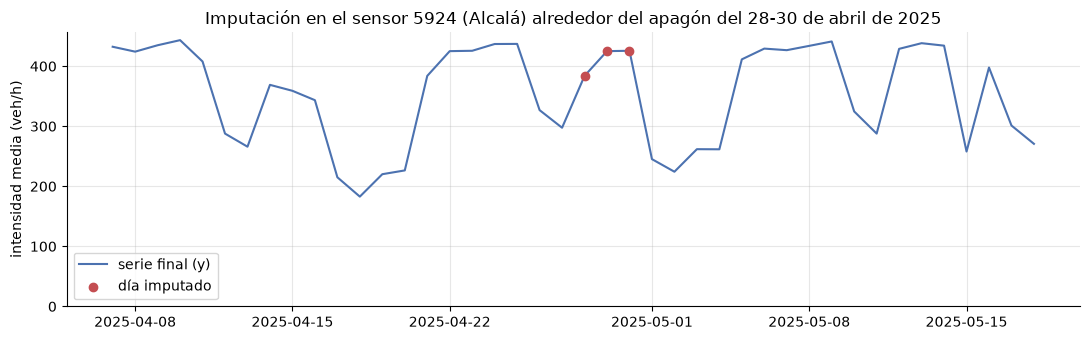

In [5]:
# Ejemplo de imputación: un sensor durante el apagón de abril de 2025
ejemplo = train[(train["unique_id"] == "5924") & train["ds"].between("2025-04-07", "2025-05-18")]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(ejemplo["ds"], ejemplo["y"], color=AZUL, label="serie final (y)")
ax.scatter(ejemplo.loc[ejemplo["imputado"], "ds"], ejemplo.loc[ejemplo["imputado"], "y"],
           color=ROJO, zorder=3, label="día imputado")
ax.set(title="Imputación en el sensor 5924 (Alcalá) alrededor del apagón del 28-30 de abril de 2025",
       ylabel="intensidad media (veh/h)")
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()

**Lectura.** La serie cumple lo que pide Nixtla: formato largo, 200 series con los mismos 723 días, frecuencia diaria
(`freq="D"`: el único salto entre días consecutivos es de 1 día), sin duplicados y sin nulos. Tampoco queda ningún cero: los ceros por sensor caído se han convertido en
días con fallo y se han imputado.

Se imputa el **1,4 %** de los sensor-días, y tres de cada cuatro son por las caídas generales de la red, que afectan a
todos los sensores a la vez. Ningún sensor tiene más de 19 días imputados en dos años.

**Límite de la imputación.** Copiar el mismo día de la semana anterior falla si ese día fue festivo. Con tan pocos
días imputados el efecto es pequeño, pero es una simplificación consciente. En el ejemplo se ve otra consecuencia: el
jueves 1 y el viernes 2 de mayo, festivos, sí son datos reales y por eso bajan.

**Lectura de negocio.** Para planificar obras interesa el nivel de tráfico de un día normal. Un día en que el sensor
estuvo caído no dice nada de la calle, así que es preferible un valor imputado razonable a un cero que haría parecer
que ese día no pasó nadie.

## 2. Con qué series se trabaja en E1: el total y una muestra de 10

El handout pide evaluar en E1 **el total más una muestra de unas 10 series** que cubran comportamientos distintos, y
dejar las 200 para E2.

- **Total:** suma de la intensidad media de los 200 sensores cada día. Resume el tráfico urbano de la ciudad.
- **Muestra:** los 200 sensores se ordenan por su intensidad media y se toma uno de cada décima parte (percentiles
  5, 15, ..., 95). Así entran calles de barrio, calles medias y grandes ejes, sin elegir a mano.

In [6]:
total = sd.total(train).set_index("ds")["y"]

# Perfil de cada sensor: nivel, peso del fin de semana, caída de agosto y cambio entre los dos años
fin_semana = train["ds"].dt.day_of_week >= 5
agosto = train["ds"].dt.month == 8
ANIO1 = train["ds"] < "2025-10-25"            # 1 nov 2024 – 24 oct 2025
ANIO2 = train["ds"] >= "2025-11-01"           # 1 nov 2025 – 24 oct 2026
g = lambda mascara: train[mascara].groupby("unique_id")["y"].mean()
perfil = pd.DataFrame({
    "media": train.groupby("unique_id")["y"].mean(),
    "finde/laborable": g(fin_semana) / g(~fin_semana),
    "agosto/resto": g(agosto) / g(~agosto),
    "cambio año 2 (%)": (g(ANIO2) / g(ANIO1) - 1) * 100,
})
perfil.index = perfil.index.astype(int)
perfil = perfil.join(seleccion[["distrito", "nombre"]])
perfil.index = perfil.index.astype(str)

MUESTRA = sd.muestra(train, n=10)
print("Sensores de la muestra:", MUESTRA)
perfil.loc[MUESTRA]

Sensores de la muestra: ['5683', '6353', '6126', '4835', '10910', '3484', '11011', '5924', '6015', '4018']


,media,finde/laborable,agosto/resto,cambio año 2 (%),distrito,nombre
unique_id,,,,,,
5683,29.96,0.93,0.92,-9.47,6,Lope de Haro O-E - Berruguete-Juán Risco
6353,68.38,0.92,0.44,8.76,21,Jardines de Aranjuez - Paseo Alameda de Osuna-Av. Logroño
6126,92.34,0.79,0.71,-2.10,14,Camino Vinateros - M-30-Manuel Machado
4835,132.12,0.83,0.87,-17.30,17,"VILLAFUERTE, 23 N-S(VILLAJOYOSA-CTRA.VILLAVERDE)"
10910,169.69,0.77,0.89,31.34,13,Av. Entrevías - Peal-Serena
3484,213.85,0.70,0.89,8.27,17,AV. REAL PINTO N-S(RESINA-SAN EZEQUIEL)
11011,276.99,0.74,0.56,0.93,16,Av. Machupichu - Av. Papa Negro-Av. Piceas
5924,368.68,0.69,0.73,-1.31,20,Alcalá - Miguel Yuste-San Romualdo
6015,462.45,0.58,0.55,-0.43,15,Arturo Soria - Arturo Baldasano-José Silva


**Lectura.** La muestra recorre todo el rango, de una calle de barrio con unos 30 veh/h de media a un lateral de la
M-30 con más de 700. Y no solo cambia el nivel: hay sensores donde el fin de semana casi no baja y otros donde cae a
la mitad, y sensores donde agosto se hunde y otros donde apenas se nota.

**Lectura de negocio.** No existe "una" ventana de obra buena para toda la ciudad. En una calle residencial el fin de
semana ahorra poco tráfico; en un eje de oficinas, mucho. Por eso el encargo pide predecir punto a punto.

## 3. Gráfico temporal y medias móviles

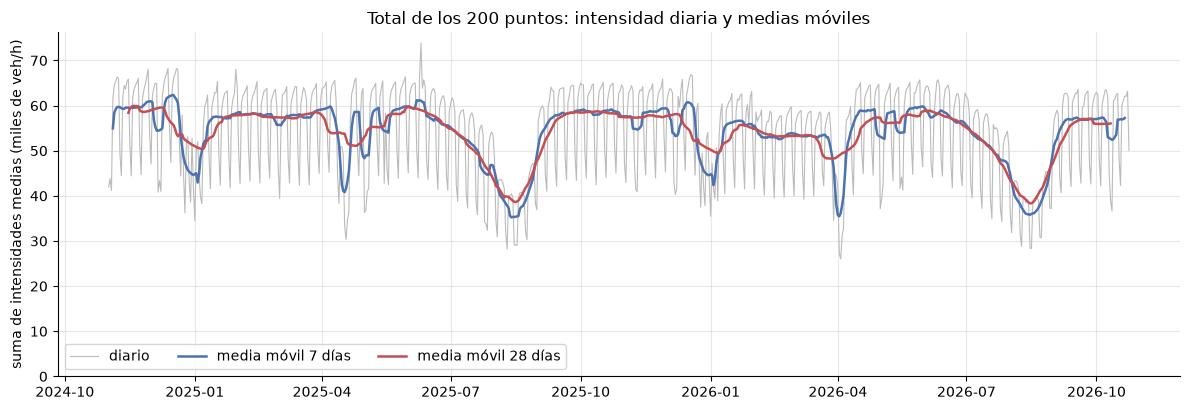

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(total.index, total / 1e3, color=GRIS, linewidth=0.8, label="diario")
ax.plot(total.index, total.rolling(7, center=True).mean() / 1e3, color=AZUL, linewidth=1.8, label="media móvil 7 días")
ax.plot(total.index, total.rolling(28, center=True).mean() / 1e3, color=ROJO, linewidth=1.8, label="media móvil 28 días")
ax.set(title="Total de los 200 puntos: intensidad diaria y medias móviles",
       ylabel="suma de intensidades medias (miles de veh/h)")
ax.set_ylim(0, None)
ax.legend(ncol=3, loc="lower left")
plt.tight_layout()

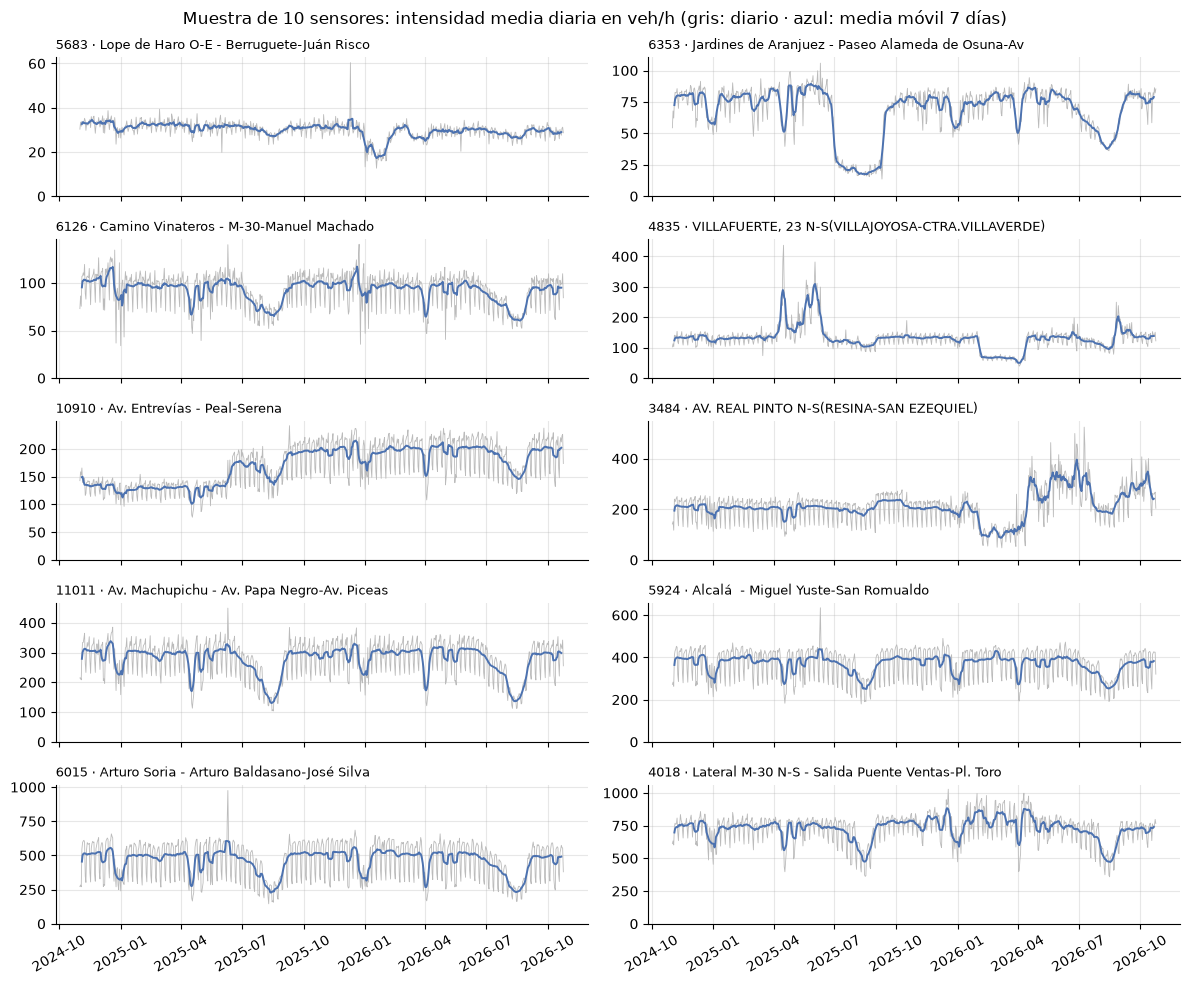

In [8]:
fig, ejes = plt.subplots(5, 2, figsize=(12, 10), sharex=True)
for ax, uid in zip(ejes.ravel(), MUESTRA):
    s = train[train["unique_id"] == uid].set_index("ds")["y"]
    ax.plot(s.index, s, color=GRIS, linewidth=0.6)
    ax.plot(s.index, s.rolling(7, center=True).mean(), color=AZUL, linewidth=1.4)
    ax.set_title(f"{uid} · {perfil.loc[uid, 'nombre'][:48]}", fontsize=9, loc="left")
    ax.set_ylim(0, None)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Muestra de 10 sensores: intensidad media diaria en veh/h (gris: diario · azul: media móvil 7 días)")
plt.tight_layout()

**Lectura.**
- **La media móvil de 7 días** elimina el ciclo semanal y deja ver el año: un nivel estable casi todo el curso,
  hundimientos cortos en Navidad y Semana Santa y un valle largo y profundo en agosto.
- **La media móvil de 28 días** muestra que no hay tendencia sostenida: el nivel de otoño de 2026 es parecido al de
  otoño de 2024, algo por debajo. Sí se aprecia que los primeros meses de 2026 van más bajos que los de 2025.
- **La serie diaria** oscila mucho dentro de cada semana. Esa oscilación es el ciclo de laborables y fines de
  semana, no ruido.
- **Los sensores comparten la forma general**, pero cada uno tiene sus particularidades: escalones de nivel, tramos
  más ruidosos o caídas propias que no aparecen en el total.

**Lectura de negocio.** Las ventanas de menos tráfico se repiten cada año en las mismas fechas, así que son
previsibles con mucha antelación. Agosto es la gran ventana para obras largas; Navidad y Semana Santa sirven para
actuaciones de pocos días.

## 4. Estacionalidad semanal

,media (veh/h),% respecto a mar-jue
lun,"56,514.00",-4.43
mar,"58,933.00",-0.34
mié,"59,280.00",0.25
jue,"59,185.00",0.09
vie,"58,088.00",-1.77
sáb,"45,618.00",-22.85
dom,"40,734.00",-31.11


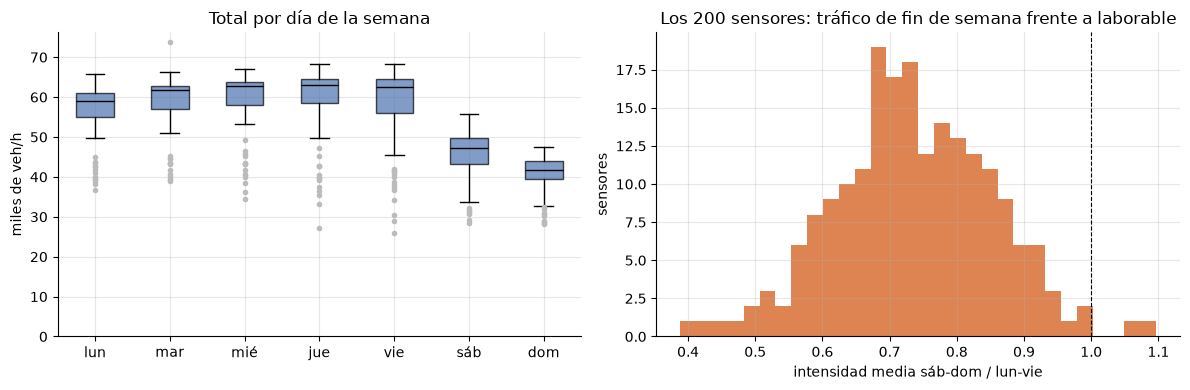

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
por_dia = [total[total.index.day_of_week == d] / 1e3 for d in range(7)]
cajas = ax[0].boxplot(por_dia, tick_labels=DIAS_SEMANA, patch_artist=True, medianprops={"color": "black"},
                      flierprops={"markersize": 3, "markerfacecolor": GRIS, "markeredgecolor": GRIS})
for caja in cajas["boxes"]:
    caja.set(facecolor=AZUL, alpha=0.7)
ax[0].set(title="Total por día de la semana", ylabel="miles de veh/h")
ax[0].set_ylim(0, None)

ax[1].hist(perfil["finde/laborable"], bins=30, color=NARANJA)
ax[1].axvline(1, color="black", linewidth=0.8, linestyle="--")
ax[1].set(title="Los 200 sensores: tráfico de fin de semana frente a laborable",
          xlabel="intensidad media sáb-dom / lun-vie", ylabel="sensores")
plt.tight_layout()

semanal = total.groupby(total.index.day_of_week).mean()
ref = semanal[[1, 2, 3]].mean()
pd.DataFrame({"media (veh/h)": semanal.round(0), "% respecto a mar-jue": (semanal / ref - 1) * 100}).set_axis(DIAS_SEMANA)

**Lectura.**
- De **martes a jueves** el tráfico es prácticamente idéntico. El lunes queda un 4 % por debajo y el viernes un 2 %.
- El **sábado cae un 23 %** y el **domingo un 31 %** respecto a un día central de la semana.
- Los puntos sueltos por debajo de las cajas de los laborables son festivos y vacaciones (sección 5).
- El peso del fin de semana cambia mucho de un sensor a otro: en la mitad de los sensores el fin de semana lleva
  entre el 66 % y el 82 % del tráfico de un laborable, pero hay casos por debajo del 50 % y dos sensores con **más**
  tráfico en fin de semana.

**Lectura de negocio.** El domingo es, cada semana, el día con menos tráfico para cortar una calle, y el ahorro
medio es de casi un tercio. Pero antes de programar una obra en fin de semana hay que mirar el sensor concreto: en
zonas de ocio o comerciales el fin de semana no es una ventana tranquila.

**Para el modelado.** La estacionalidad dominante es de 7 días: `season_length = 7` es la elección natural para el
*seasonal naïve*.

## 5. Estacionalidad anual y festivos

,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
ds,,,,,,,,,,,,
2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"58,569.00","55,126.00"
2025,"55,033.00","57,904.00","56,897.00","54,451.00","55,976.00","57,676.00","50,989.00","38,883.00","57,456.00","59,135.00","56,902.00","54,633.00"
2026,"53,328.00","53,290.00","52,017.00","53,490.00","56,046.00","57,891.00","51,526.00","38,696.00","56,576.00","55,970.00",NaN,NaN


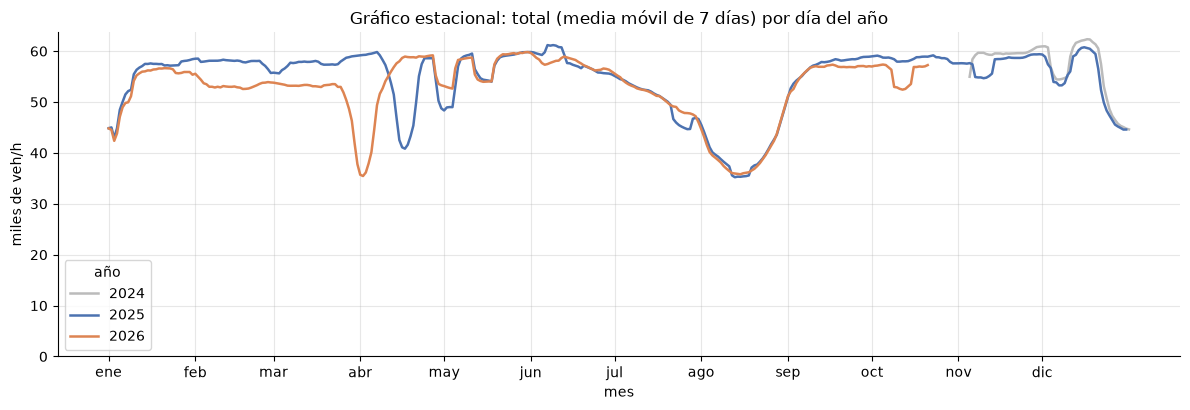

In [10]:
suave = total.rolling(7, center=True).mean() / 1e3
fig, ax = plt.subplots(figsize=(12, 4.2))
for anio, color in zip([2024, 2025, 2026], [GRIS, AZUL, NARANJA]):
    s = suave[suave.index.year == anio]
    ax.plot(s.index.day_of_year, s, color=color, linewidth=1.8, label=str(anio))
ax.set_xticks([pd.Timestamp(2025, m, 1).day_of_year for m in range(1, 13)], MESES)
ax.set(title="Gráfico estacional: total (media móvil de 7 días) por día del año",
       ylabel="miles de veh/h", xlabel="mes")
ax.set_ylim(0, None)
ax.legend(title="año")
plt.tight_layout()

mensual = total.groupby([total.index.year, total.index.month]).mean().unstack(0).round(0)
mensual.index = MESES
mensual.T

In [11]:
# Días anómalos: cada día se compara con la mediana del mismo día de la semana en las 4 semanas de antes y de después
vecinos = pd.concat([total.shift(7 * k) for k in (-4, -3, -2, -1, 1, 2, 3, 4)], axis=1).median(axis=1)
desvio = ((total / vecinos - 1) * 100).dropna()

# Festivos de Madrid capital (lista manual en serie_diaria.py; en E2 se tomará de una fuente oficial)
FESTIVOS = sd.FESTIVOS
anomalos = desvio.nsmallest(24).to_frame("% respecto a un día equivalente")
anomalos["día"] = [DIAS_SEMANA[d] for d in anomalos.index.day_of_week]
anomalos["festivo conocido"] = [FESTIVOS.get(f"{d:%Y-%m-%d}", "—") for d in anomalos.index]
print(f"De los 24 días con mayor caída, {(anomalos['festivo conocido'] != '—').sum()} son festivos de la lista.")
anomalos

De los 24 días con mayor caída, 22 son festivos de la lista.


,% respecto a un día equivalente,día,festivo conocido
ds,,,
2026-04-03,-55.81,vie,Viernes Santo
2026-04-02,-53.47,jue,Jueves Santo
2025-04-18,-51.84,vie,Viernes Santo
2025-04-17,-48.04,jue,Jueves Santo
2025-01-01,-45.07,mié,Año Nuevo
2025-05-01,-43.78,jue,Día del Trabajo
2025-05-02,-43.61,vie,Comunidad de Madrid
2024-12-25,-43.27,mié,Navidad
2026-01-01,-42.89,jue,Año Nuevo


**Lectura.**
- **La forma del año se repite:** mismas subidas, mismos valles y casi en las mismas fechas. De mayo en adelante las
  curvas de 2025 y 2026 se superponen casi exactamente.
- **El nivel no es idéntico:** de enero a marzo, 2026 va entre un 3 % y un 9 % por debajo de 2025 (sección 8).
- **Agosto** es el mes más bajo con diferencia: unos 39.000 veh/h de media frente a 55.000–59.000 en un mes normal,
  alrededor de un **tercio menos**. Julio ya baja un 10 %.
- **Semana Santa** se mueve en el calendario (mediados de abril en 2025, principios de abril en 2026) y arrastra su
  valle con ella.
- **Los días con mayor caída son casi todos festivos.** Jueves y Viernes Santo pierden la mitad del tráfico, y Año
  Nuevo, Navidad y el 1 de mayo más del 40 %. Los dos que no están en la lista son el Sábado Santo y el 31 de
  diciembre, que tampoco son días normales.

**Lectura de negocio.** Un festivo entre semana ofrece una ventana de obra tan buena como un domingo o mejor, y se
conoce con un año de antelación.

**Para el modelado.** Un *seasonal naïve* semanal copia el martes pasado para predecir el martes próximo, así que
fallará en las semanas con festivo y al entrar y salir de agosto. Ahí es donde un modelo con calendario puede ganar.

## 6. Autocorrelación (ACF)

Correlación entre cada día y el mismo día de la semana un año antes (retardo 364): 0.80


retardo (días),1,2,7,14,21,28
autocorrelación,0.61,0.19,0.74,0.66,0.55,0.51


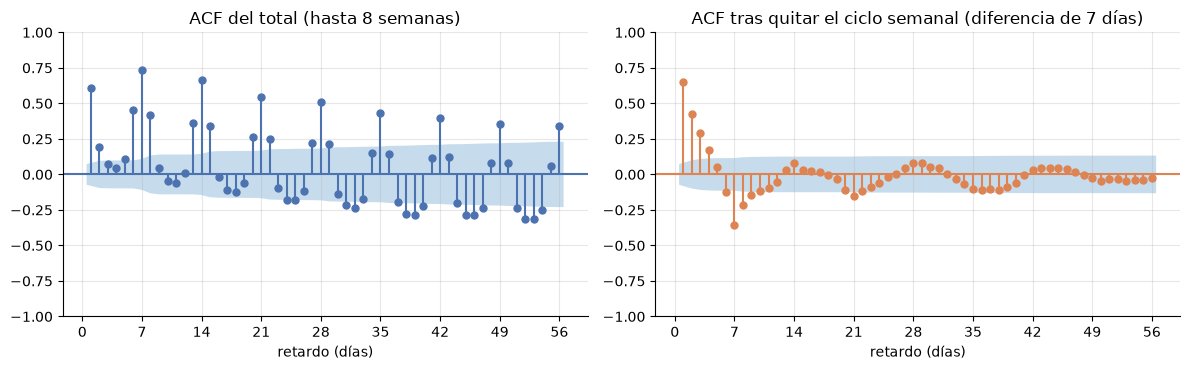

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(total, lags=56, ax=ax[0], color=AZUL, vlines_kwargs={"colors": AZUL}, zero=False)
ax[0].set(title="ACF del total (hasta 8 semanas)", xlabel="retardo (días)")
ax[0].set_xticks(range(0, 57, 7))
plot_acf(total.diff(7).dropna(), lags=56, ax=ax[1], color=NARANJA, vlines_kwargs={"colors": NARANJA}, zero=False)
ax[1].set(title="ACF tras quitar el ciclo semanal (diferencia de 7 días)", xlabel="retardo (días)")
ax[1].set_xticks(range(0, 57, 7))
plt.tight_layout()

rho = pd.Series(acf(total, nlags=28), name="autocorrelación").loc[[1, 2, 7, 14, 21, 28]]
rho.index.name = "retardo (días)"
print(f"Correlación entre cada día y el mismo día de la semana un año antes (retardo 364): {total.autocorr(364):.2f}")
rho.to_frame().T

**Lectura.**
- La ACF tiene **picos cada 7 días** (0,74 en el retardo 7; 0,66 en el 14) que decaen despacio: el ciclo semanal es
  la estructura principal de la serie.
- La autocorrelación con el **día anterior** es 0,61, pero cae a 0,19 a dos días: ayer se parece a hoy sobre todo
  cuando los dos son laborables.
- A un año de distancia (retardo 364, mismo día de la semana) la correlación es muy alta, 0,80: es la estacionalidad
  anual. Solo hay un año de pares para calcularla, así que es una cifra orientativa.
- Tras diferenciar a 7 días queda autocorrelación positiva en los primeros retardos y un pico negativo en el 7. El
  ciclo semanal no lo explica todo: cuando una semana viene baja (vacaciones), los días siguientes también.

**Para el modelado.** El retardo más útil es el 7 (misma jornada de la semana anterior), seguido del 1 y del 14. Esos
son los retardos que conviene dar al modelo global en E2.

## 7. Descomposición

El handout orienta dos estacionalidades: 7 (semanal) y 365 (anual). Una descomposición MSTL con las dos necesita
varios ciclos completos de cada una, y aquí el máximo permitido son 2 años: hay 103 ciclos semanales pero **ni
siquiera dos ciclos anuales completos** (723 días). Con eso no se puede separar con rigor la estacionalidad anual de
la tendencia.

**Decisión.** Se descompone con **STL de periodo 7**, en versión robusta para que los festivos no deformen el patrón
semanal. La componente de tendencia recoge entonces el nivel y también el movimiento anual (agosto, Navidad), que ya
se ha estudiado en la sección 5 superponiendo los dos años.

Fuerza de la estacionalidad semanal: 0.70  ·  fuerza de la tendencia: 0.61  (0 = nula, 1 = total)
Amplitud del ciclo semanal: 46% del nivel medio


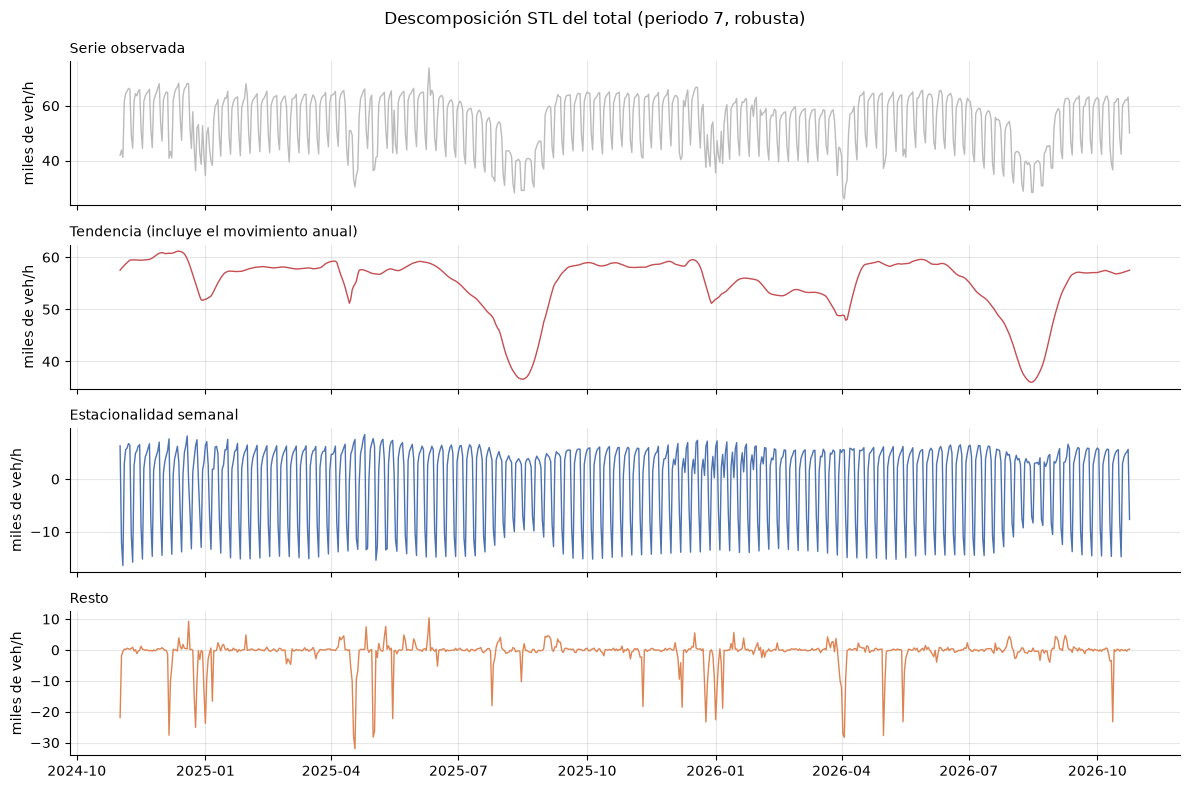

In [13]:
stl = STL(total, period=7, robust=True).fit()
fig, ax = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for a, (nombre, comp, color) in zip(ax, [("Serie observada", total, GRIS), ("Tendencia (incluye el movimiento anual)", stl.trend, ROJO),
                                         ("Estacionalidad semanal", stl.seasonal, AZUL), ("Resto", stl.resid, NARANJA)]):
    a.plot(comp.index, comp / 1e3, color=color, linewidth=1)
    a.set_title(nombre, loc="left", fontsize=10)
    a.set_ylabel("miles de veh/h")
fig.suptitle("Descomposición STL del total (periodo 7, robusta)")
plt.tight_layout()

fuerza_est = 1 - stl.resid.var() / (stl.resid + stl.seasonal).var()
fuerza_tend = 1 - stl.resid.var() / (stl.resid + stl.trend).var()
print(f"Fuerza de la estacionalidad semanal: {fuerza_est:.2f}  ·  fuerza de la tendencia: {fuerza_tend:.2f}  (0 = nula, 1 = total)")
print(f"Amplitud del ciclo semanal: {(stl.seasonal.max() - stl.seasonal.min()) / total.mean():.0%} del nivel medio")

**Lectura.**
- La **estacionalidad semanal** es fuerte (0,70 sobre 1) y su amplitud se **encoge en agosto**: en vacaciones la
  diferencia entre laborable y fin de semana es menor. El patrón semanal no es fijo todo el año.
- La **tendencia** no crece ni decrece de forma sostenida; lo que dibuja es el ciclo anual, con los valles de agosto,
  Navidad y Semana Santa.
- El **resto** es pequeño casi siempre y se dispara en días concretos: son los festivos, que ni la tendencia ni el
  ciclo semanal pueden explicar.

**Lectura de negocio.** El tráfico de una calle se explica casi por completo con tres preguntas: qué día de la semana
es, en qué época del año estamos y si es festivo. Las tres se conocen de antemano, lo que hace razonable prever a una
semana vista.

## 8. ¿Qué cambia con el tiempo? Rupturas

Se compara el primer año (1 nov 2024 – 24 oct 2025) con el segundo (1 nov 2025 – 24 oct 2026), en el total y sensor
a sensor.

Total · media del año 1: 54,720 veh/h · año 2: 53,281 veh/h · cambio: -2.6%


Sensores que cambian más de un 20 % en un sentido u otro: 9 de 200


,nov,dic,ene,feb,mar,abr,may,jun,jul,ago,sep,oct
cambio año 2 respecto al año 1 (%),-2.85,-0.90,-3.10,-7.97,-8.58,-1.76,0.13,0.37,1.05,-0.48,-1.53,-5.67


,media,cambio año 2 (%),distrito,nombre
unique_id,,,,
5149,41.47,-68.92,10,ILLESCAS ENTRE Pº EXTREMADURA Y SESEÑA SENTIDO O-E
10562,335.62,-42.05,8,AV. CAMINO DE SANTIAGO S-N
7087,106.96,-27.97,1,BAILEN N-S (GIRO A MAYOR)(SALIDA TUNEL-MAYOR)
5899,267.17,-26.49,8,AV. CARDENAL HERRERA ORIA 124 S-N(ACCESO M-607-ISLA DE S...
10902,38.56,37.98,17,MIGUEL SOLAS O-E (INTERIOR)
5746,404.53,35.20,5,Av. Pio XII O-E (Bambu-Av. Burgos)
10910,169.69,31.34,13,Av. Entrevías - Peal-Serena
10857,77.58,24.11,8,(CARRIL BUS) SANTO DOMINGO DE LA CALZADA E-O(SAUCEDA-VAL...


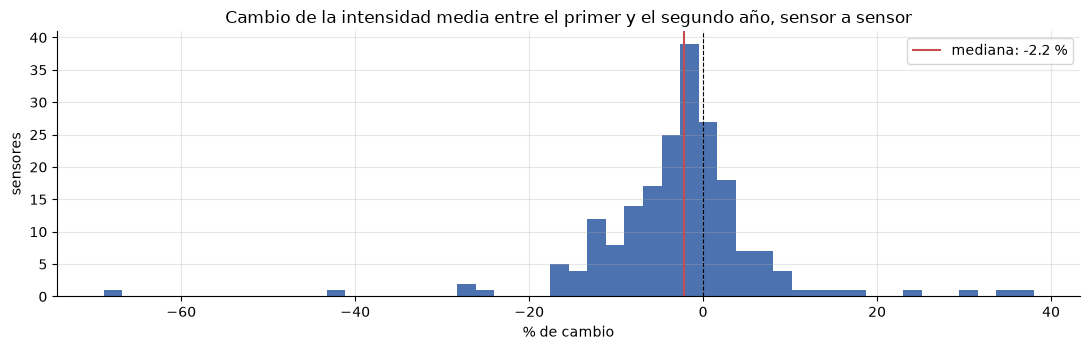

In [14]:
anio1, anio2 = total[total.index < "2025-10-25"], total[total.index >= "2025-11-01"]
print(f"Total · media del año 1: {anio1.mean():,.0f} veh/h · año 2: {anio2.mean():,.0f} veh/h · "
      f"cambio: {(anio2.mean() / anio1.mean() - 1):+.1%}")

cambio = perfil["cambio año 2 (%)"]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.hist(cambio, bins=50, color=AZUL)
ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
ax.axvline(cambio.median(), color=ROJO, linewidth=1.5, label=f"mediana: {cambio.median():+.1f} %")
ax.set(title="Cambio de la intensidad media entre el primer y el segundo año, sensor a sensor",
       xlabel="% de cambio", ylabel="sensores")
ax.legend()
plt.tight_layout()

print(f"Sensores que cambian más de un 20 % en un sentido u otro: {(cambio.abs() > 20).sum()} de {len(cambio)}")

# ¿Dónde se concentra la bajada? Mismo mes de un año y del siguiente
m1 = anio1.groupby(anio1.index.month).mean()
m2 = anio2.groupby(anio2.index.month).mean()
por_mes = ((m2 / m1 - 1) * 100).reindex([11, 12, *range(1, 11)])
por_mes.index = [MESES[m - 1] for m in por_mes.index]
display(por_mes.to_frame("cambio año 2 respecto al año 1 (%)").T)

extremos = pd.concat([perfil.nsmallest(4, "cambio año 2 (%)"), perfil.nlargest(4, "cambio año 2 (%)")])
extremos[["media", "cambio año 2 (%)", "distrito", "nombre"]]

,pct_ceros,media,media_sin_ceros,año
mes,,,,
2025-01-01,1.79,275.89,280.93,2025
2025-02-01,1.88,290.71,296.28,2025
2025-03-01,1.76,285.73,290.84,2025
2025-04-01,1.72,270.45,275.17,2025
2026-01-01,2.41,266.48,273.06,2026
2026-02-01,2.75,270.05,277.69,2026
2026-03-01,2.79,261.23,268.72,2026
2026-04-01,2.20,268.93,274.97,2026


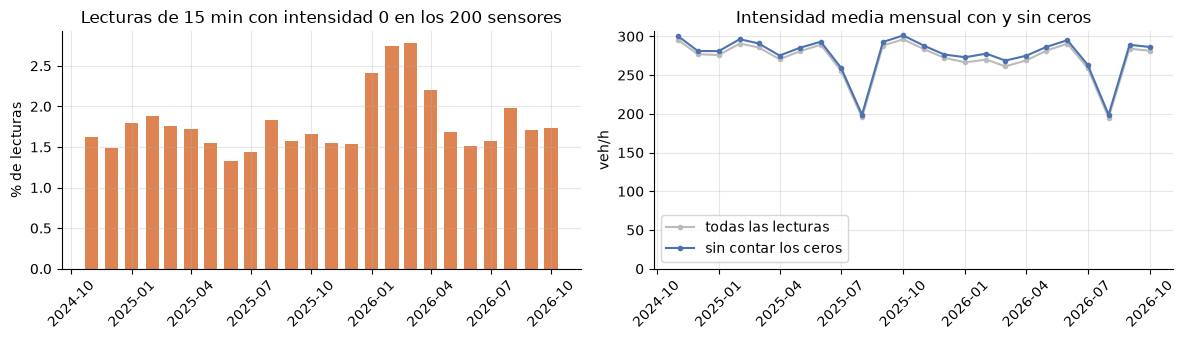

In [15]:
# Comprobación: ¿la bajada de principios de 2026 es real o son los ceros de relleno de la fuente?
ceros = sd.ceros_mensuales(seleccion.index)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(ceros.index, ceros["pct_ceros"], width=20, color=NARANJA)
ax[0].set(title="Lecturas de 15 min con intensidad 0 en los 200 sensores", ylabel="% de lecturas")
ax[1].plot(ceros.index, ceros["media"], color=GRIS, marker="o", markersize=3, label="todas las lecturas")
ax[1].plot(ceros.index, ceros["media_sin_ceros"], color=AZUL, marker="o", markersize=3, label="sin contar los ceros")
ax[1].set(title="Intensidad media mensual con y sin ceros", ylabel="veh/h")
ax[1].set_ylim(0, None)
ax[1].legend()
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
ceros.loc["2025-01":"2025-04"].assign(año=2025).pipe(lambda a: pd.concat([a, ceros.loc["2026-01":"2026-04"].assign(año=2026)]))

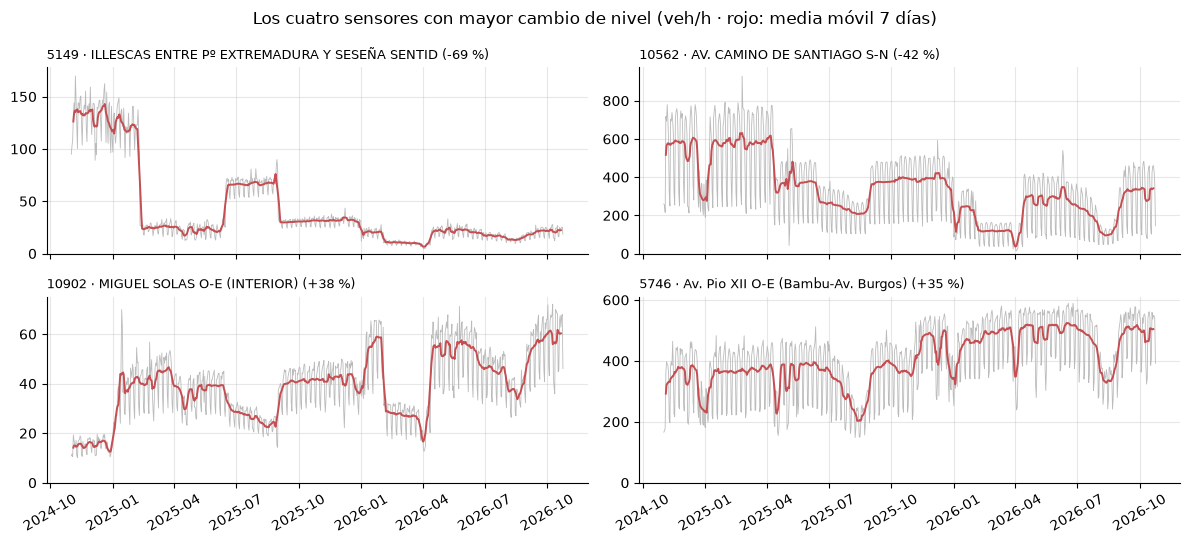

In [16]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True)
for ax, uid in zip(ejes.ravel(), [*perfil.nsmallest(2, "cambio año 2 (%)").index, *perfil.nlargest(2, "cambio año 2 (%)").index]):
    s = train[train["unique_id"] == uid].set_index("ds")["y"]
    ax.plot(s.index, s, color=GRIS, linewidth=0.6)
    ax.plot(s.index, s.rolling(7, center=True).mean(), color=ROJO, linewidth=1.4)
    ax.set_title(f"{uid} · {perfil.loc[uid, 'nombre'][:45]} ({perfil.loc[uid, 'cambio año 2 (%)']:+.0f} %)", fontsize=9, loc="left")
    ax.set_ylim(0, None)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Los cuatro sensores con mayor cambio de nivel (veh/h · rojo: media móvil 7 días)")
plt.tight_layout()

**Lectura.**
- **En conjunto el tráfico baja un 2,6 %** del primer año al segundo, y la bajada se concentra en los primeros
  meses de 2026: de enero a marzo va entre un 3 % y un 9 % por debajo de 2025, y de mayo a septiembre vuelve al mismo nivel. (Octubre
  de 2026 no es comparable: le falta la semana de test e incluye el festivo del lunes 12.)
- **No es un artefacto de los ceros.** De enero a abril de 2026 hay más lecturas a cero que el resto del periodo
  (la fuente rellena huecos con ceros), pero quitándolos la media de esos meses sigue por debajo de la de 2025. Los
  ceros explican como mucho un punto de la diferencia. La bajada está en los datos, aunque con dos años no se puede
  saber si es una anomalía de ese invierno o el inicio de un cambio.
- **La mayoría de los sensores se mueve poco**, pero unos cuantos cambian más de un 20 %, y en los gráficos se ve que
  son **rupturas de nivel**: el sensor pasa de un régimen a otro en una fecha concreta y se queda ahí. Es lo que
  produce una obra, un cambio de sentido o una reordenación del tráfico en esa calle.
- No hay ningún escalón común a toda la red. Los 8 días de caída general ya están imputados.

**Lectura de negocio.** Las rupturas son, con toda probabilidad, el propio efecto de lo que el encargo quiere
planificar: obras y cambios de ordenación. Avisan de un riesgo real: tras una ruptura, el histórico anterior deja de
servir para ese punto.

**Para el modelado.** Un método que promedia todo el histórico (la media) estará mal calibrado en los sensores con
ruptura; los que miran solo lo reciente (naïve, seasonal naïve) se adaptan solos. Es un motivo para esperar que la
media sea el peor baseline.

## 9. Las trampas del handout: detectada, decidida y justificada

| Trampa | Cómo se detecta | Qué se decide | Por qué |
|---|---|---|---|
| **Cada mes son ~780 MB de CSV y no cabe leerlo entero** | Un mes tiene unos 13 M de filas; los 24 meses, 317 M (notebook 01, sección 2) | `descarga_bruto.py` convierte cada CSV a Parquet **por bloques**, sin cargarlo entero. Después se consulta con DuckDB filtrando por los 200 sensores, y a pandas solo llega la tabla diaria (146.000 filas) | Guardar el bruto completo en Parquet (1 GB) permite elegir los sensores con criterio en lugar de a ciegas, y repetir cualquier cálculo sin volver a descargar |
| **Puntos que se dan de alta y de baja** | Cruce con el fichero mensual de ubicación: 131 altas y 30 bajas entre los urbanos (notebook 01, sección 6) | Solo entran sensores presentes en **todas** las fichas y con datos el primer y el último día | Un modelo global con 2 años de histórico necesita series completas; una serie que empieza a mitad de periodo no tiene con qué aprender la estacionalidad anual |
| **Ceros por sensor caído ≠ calle vacía** | Reglas *todo a cero* y *ceros de día* (≥ 50 % de ceros entre las 7 y las 22 h). En enero de 2026 la fuente rellenó huecos con ceros (notebook 01, sección 5.2) | Esos días se marcan como fallo y se **imputan**; los ceros de madrugada se respetan como reales | De día siempre pasan coches por una calle urbana: un cero sostenido en horas de luz es una avería. Tratarlo como dato real enseñaría al modelo caídas de tráfico que no existieron |

Además de las tres del handout, han aparecido otras dos que afectan a la serie:

| Trampa | Qué se decide |
|---|---|
| **Caídas generales de la red** (8 días, entre ellos el apagón del 28-30 de abril de 2025) | Se imputan en todos los sensores, porque ese día la intensidad está infravalorada en toda la ciudad |
| **Días incompletos** (faltan cuartos de hora) | Si llega menos del 75 % de las lecturas, el día se imputa; si llega más, se usa la media de las que hay |

## 10. Conclusiones

**La serie.** 200 sensores × 723 días en formato largo, frecuencia diaria, sin huecos. `y` es la intensidad media del
día en veh/h. Se imputa el 1,4 % de los sensor-días, siempre mirando hacia atrás.

**Patrones.**
- **Semanal**, el dominante: sábado −23 % y domingo −31 % respecto a un día central. Autocorrelación de 0,74 a 7 días.
- **Anual**, muy estable entre los dos años: agosto un tercio por debajo, valles cortos en Navidad y Semana Santa.
- **Festivos**: los días con mayor caída son casi todos festivos, con hasta un 50 % menos de tráfico.

**Qué cambia.** El total baja un 2,6 % de un año a otro, sin tendencia sostenida: la bajada se concentra en el
primer trimestre de 2026. Algunos sensores tienen rupturas de nivel propias, compatibles con obras o cambios de
ordenación.

**Heterogeneidad.** El nivel va de unas decenas a más de mil veh/h, y el peso del fin de semana y de agosto cambia
mucho entre sensores. Es el argumento para un modelo global que aprenda de todos a la vez pero prediga cada uno.

**Siguiente paso (notebook 03).** Partición temporal con la semana de test y ventana rodante, y los cuatro baselines
(media, naïve, seasonal naïve con `season_length = 7` y drift) evaluados con MAE, RMSE y MASE.